# Chapter 7: Social Welfare, Inequality, and Compensation

This notebook reruns four worked examples from the chapter: a transfer under concave utility with and without leakage, the Atkinson trade between mean income and equality, a payment that makes an office assignment envy-free, and the Kaldor-Hicks test for a bypass. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def utility_curve(ax, u, x_max, x_min=0.0, col="navy", text=None, n=300):
    """Plot u(x) on [x_min, x_max]; ``u`` is a vectorised function. Returns (x, u(x))."""
    x = np.linspace(x_min, x_max, n)
    y = u(x)
    ax.plot(x, y, color=color(col), linewidth=2.2)
    if text:
        label(ax, x[-1], y[-1], text, col=col, dx=-4, dy=-14, ha="right", va="top")
    return x, y


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def utilitarian_transfer(y, t, leak=0.0, u=math.sqrt):
    """Move t from the richer household y[1] to the poorer y[0]; leak is lost on the way.

    Principle: diminishing-marginal-utility-of-income. Book (ch007): y = (25, 100), u = sqrt,
    t = 9 gives (34, 91) and W1 = 15.370 against W0 = 15; with leak 5 the vector is (29, 91) and
    W2 = 14.9246 (the book prints 14.924 and a drop of about 0.076; exact drop 0.0754).
    Returns dict with incomes, utilities, W0, W and change.
    """
    low, high = y
    new = (low + t - leak, high - t)
    w0 = u(low) + u(high)
    parts = (u(new[0]), u(new[1]))
    return {"incomes": new, "utils": parts, "W0": w0, "W": parts[0] + parts[1], "change": parts[0] + parts[1] - w0}


def atkinson_ede(y, eps):
    """Equally distributed equivalent income for inequality aversion eps.

    Principle: atkinson-inequality-aversion. Book (ch007): P = (20, 80), eps = 1 gives sqrt(1,600) = 40;
    Q = (30, 60) gives sqrt(1,800) = 42.426; eps = 0 gives the means 50 and 45.
    """
    n = len(y)
    if abs(eps - 1) < 1e-12:
        return math.exp(sum(math.log(v) for v in y) / n)
    return (sum(v ** (1 - eps) for v in y) / n) ** (1 / (1 - eps))


def atkinson_index(y, eps):
    """Atkinson index A = 1 - EDE / mean. Principle: atkinson-inequality-aversion.

    Book (ch007): A_P(1) = 1 - 40/50 = 0.20; A_Q(1) = 1 - 42.426/45 = 0.057.
    """
    return 1 - atkinson_ede(y, eps) / (sum(y) / len(y))


def envy_check(values, t):
    """Two agents, two objects, A gets object 0 and pays t to B (who gets object 1).

    values = ((A's value of object 0, of object 1), (B's value of object 0, of object 1)).
    Principle: envy-freeness. Book (ch007): ((120, 80), (100, 90)), t = 15 gives A own 105 vs other 95
    and B own 105 vs other 85; envy-free for 5 <= t <= 20.
    Returns own and other package values, envy flags, and the envy-free interval of t.
    """
    (a0, a1), (b0, b1) = values
    a_own, a_other = a0 - t, a1 + t
    b_own, b_other = b1 + t, b0 - t
    return {"a_own": a_own, "a_other": a_other, "b_own": b_own, "b_other": b_other,
            "a_envies": a_other > a_own, "b_envies": b_other > b_own,
            "envy_free": a_other <= a_own and b_other <= b_own,
            "interval": ((b0 - b1) / 2, (a0 - a1) / 2)}


def compensation_test(G, L, R, admin=0.0):
    """Kaldor-Hicks residual S = G - L - R - admin.

    Principle: kaldor-hicks-compensation-principle. Book (ch007): 125 - 80 - 30 = 15; with paid
    compensation costing 4 to administer, 15 - 4 = 11; with R = 50, 125 - 80 - 50 = -5.
    """
    S = G - L - R - admin
    return {"S": S, "passes": S > 0}


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(utilitarian_transfer=utilitarian_transfer, atkinson_ede=atkinson_ede, atkinson_index=atkinson_index, envy_check=envy_check, compensation_test=compensation_test)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'diminishing-marginal-utility-of-income': {'y': (25, 100),
                                            'W0': 15,
                                            't': 9,
                                            'after': (34, 91),
                                            'W1': 15.37,
                                            'gain': 0.37,
                                            'mu': (0.1, 0.05),
                                            'leak': 5,
                                            'after_leak': (29, 91),
                                            'W2_printed_as': 14.924,
                                            'W2_exact_4dp': 14.9246,
                                            'drop_printed_as': 0.076,
                                            'drop_exact_4dp': 0.0754},
 'atkinson-inequality-aversion': {'P': (20, 80),
                                  'Q': (30, 60),
                                  'mean_P': 50,
                                  'mean_Q': 45,
                                  'ede_P': 40,
                                  'A_P': 0.2,
                                  'ede_Q': 42.426,
                                  'A_Q': 0.057,
                                  'ede_P_eps0': 50,
                                  'ede_Q_eps0': 45},
 'envy-freeness': {'A': (120, 80),
                   'B': (100, 90),
                   't': 15,
                   'a_own': 105,
                   'a_other': 95,
                   'b_own': 105,
                   'b_other': 85,
                   'b_envy_t0': 10,
                   'total': 210,
                   'total_reversed': 180},
 'kaldor-hicks-compensation-principle': {'G': 125,
                                         'L': 80,
                                         'R': 30,
                                         'S': 15,
                                         'admin': 4,
                                         'S_admin': 11,
                                         'R_high': 50,
                                         'S_high': -5},
 'constructed': {'diminishing-marginal-utility-of-income': {'t': [16, 25]},
                 'atkinson-inequality-aversion': {'eps': [0.5, 2]},
                 'envy-freeness': {'t': [5, 25]},
                 'kaldor-hicks-compensation-principle': {'R': [40]}}}


def sum_digits(a, b, start=3):
    """Fewest decimals (from ``start``) at which round(a) + round(b) equals round(a + b)."""
    for d in range(start, 8):
        if round(round(a, d) + round(b, d), d) == round(a + b, d):
            return d
    return 8


def transfer_picture(t=9, leak=0):
    r = public.utilitarian_transfer((25, 100), t, leak)
    (yl, yh), (ul, uh) = r["incomes"], r["utils"]
    d = sum_digits(ul, uh)
    fig, ax = new_figure()
    utility_curve(ax, np.sqrt, 110, text="u(y) = sqrt(y)")
    mark(ax, 25, 5, "L before (25, 5)", col="grey", dx=8, dy=-14, va="top")
    mark(ax, 100, 10, "H before (100, 10)", col="grey", dx=-8, dy=8, ha="right")
    mark(ax, yl, ul, f"L after ({num(yl, 0)}, {num(ul, d)})", col="teal", dx=8,
         dy=-14 if yl >= 40 else 8, va="top" if yl >= 40 else "bottom")
    mark(ax, yh, uh, f"H after ({num(yh, 0)}, {num(uh, d)})", col="navy", dx=-8, dy=-14, ha="right", va="top")
    ax.text(0.97, 0.06, f"W = {num(r['W'], d)} against W0 = 15", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=11, color=PALETTE["ink"], bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": "none"})
    ax.set_xlim(0, 112)
    ax.set_ylim(0, 11.5)
    ax.set_xlabel("Income y (thousands)")
    ax.set_ylabel("Evaluated utility u(y)")
    ch = r["change"]
    verdict = ("rises" if ch > 0 else "falls")
    metrics = {"Incomes after (L, H)": f"({num(yl, 0)}, {num(yh, 0)})", "Welfare W": num(r["W"], d),
               "Change from W0 = 15": plus(ch, d), "Total income": num(yl + yh, 0),
               "Marginal utility at the start (L, H)": "0.10, 0.05"}
    lost = f", and {leak} is lost on the way, so L receives {t - leak}" if leak else ""
    interp = (f"H gives up {t}{lost}. Incomes become ({num(yl, 0)}, {num(yh, 0)}), so W = sqrt({num(yl, 0)}) + "
              f"sqrt({num(yh, 0)}) = {num(ul, d)} + {num(uh, d)} = {num(r['W'], d)}. Evaluated welfare {verdict} by "
              f"{num(abs(ch), d)} from 15. At the start a unit is worth 1 / (2 x 5) = 0.10 to L and 1 / (2 x 10) = "
              f"0.05 to H.")
    steps = [f"L: {25} + {t} - {leak} = {num(yl, 0)}; H: 100 - {t} = {num(yh, 0)}",
             f"W = {num(ul, d)} + {num(uh, d)} = {num(r['W'], d)}",
             f"Change = {num(r['W'], d)} - 15 = {plus(ch, d)}"]
    alt = (f"Square-root utility curve with L moving from 25 to {num(yl, 0)} and H from 100 to {num(yh, 0)}; welfare "
           f"{num(r['W'], d)} against 15.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def atkinson_picture(eps=1):
    P, Q = (20, 80), (30, 60)
    eP, eQ = public.atkinson_ede(P, eps), public.atkinson_ede(Q, eps)
    aP, aQ = public.atkinson_index(P, eps), public.atkinson_index(Q, eps)
    winner, tie = tie_or_winner("P", eP, "Q", eQ)
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs - 0.18, [50, 45], width=0.34, color=PALETTE["light"], label="mean income")
    ax.bar(xs + 0.18, [eP, eQ], width=0.34, color=PALETTE["teal"], label=f"EDE at epsilon = {eps}")
    for x, m, e in [(0, 50, eP), (1, 45, eQ)]:
        ax.annotate(num(m, 0), (x - 0.18, m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
        ax.annotate(num(e, 2), (x + 0.18, e), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks(xs, ["P = (20, 80)", "Q = (30, 60)"])
    ax.set_ylim(0, 68)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Distribution")
    ax.set_ylabel("Income (thousands)")
    if eps == 0:
        how = "With epsilon = 0 the EDE is the mean: 50 for P and 45 for Q."
    elif eps == 1:
        how = (f"With epsilon = 1 the EDE is the geometric mean: sqrt(20 x 80) = {num(eP, 2)} and sqrt(30 x 60) = "
               f"{num(eQ, 2)}.")
    elif eps == 0.5:
        how = (f"With epsilon = 0.5, EDE = ((sqrt(y1) + sqrt(y2)) / 2)^2: P gives ((4.472 + 8.944) / 2)^2 = "
               f"{num(eP, 2)} and Q gives ((5.477 + 7.746) / 2)^2 = {num(eQ, 2)}.")
    else:
        how = (f"With epsilon = 2 the EDE is the harmonic mean: 2 / (1/20 + 1/80) = {num(eP, 2)} and 2 / (1/30 + "
               f"1/60) = {num(eQ, 2)}.")
    rank = "The two tie." if tie else f"{winner} ranks higher."
    metrics = {"EDE of P": num(eP, 2), "Atkinson index of P": num(aP, 3), "EDE of Q": num(eQ, 2),
               "Atkinson index of Q": num(aQ, 3), "Ranking": "tie" if tie else f"{winner} above {'Q' if winner == 'P' else 'P'}"}
    interp = (f"{how} {rank} The index is 1 - EDE / mean: 1 - {num(eP, 2)} / 50 = {num(aP, 3)} for P and 1 - "
              f"{num(eQ, 2)} / 45 = {num(aQ, 3)} for Q.")
    steps = [f"EDE(P) = {num(eP, 2)}, EDE(Q) = {num(eQ, 2)}", f"A(P) = 1 - {num(eP, 2)} / 50 = {num(aP, 3)}",
             f"A(Q) = 1 - {num(eQ, 2)} / 45 = {num(aQ, 3)}", f"Ranking: {'tie' if tie else winner + ' higher'}"]
    alt = (f"Bars of mean income and EDE for P and Q at epsilon {eps}: P {num(eP, 2)} against 50, Q {num(eQ, 2)} "
           f"against 45.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def envy_picture(t=15):
    r = public.envy_check(((120, 80), (100, 90)), t)
    lo, hi = r["interval"]
    fig, ax = new_figure()
    ts = np.linspace(-5, 35, 200)
    ax.plot(ts, 120 - ts, color=PALETTE["navy"], linewidth=2.2, label="A's own package 120 - t")
    ax.plot(ts, 80 + ts, color=PALETTE["navy"], linewidth=1.6, linestyle="dashed", label="A's view of B's 80 + t")
    ax.plot(ts, 90 + ts, color=PALETTE["teal"], linewidth=2.2, label="B's own package 90 + t")
    ax.plot(ts, 100 - ts, color=PALETTE["teal"], linewidth=1.6, linestyle="dashed", label="B's view of A's 100 - t")
    ax.axvspan(lo, hi, color=PALETTE["gold"], alpha=0.12)
    label(ax, (lo + hi) / 2, 62, f"envy-free for {num(lo, 0)} to {num(hi, 0)}", col="gold", dx=0, dy=0, ha="center")
    ax.axvline(t, color=PALETTE["grey"], linewidth=1.2)
    mark(ax, t, r["a_own"], col="navy")
    mark(ax, t, r["b_own"], col="teal")
    ax.set_xlim(-5, 35)
    ax.set_ylim(55, 140)
    ax.legend(loc="upper left", frameon=False, ncol=2)
    ax.set_xlabel("Transfer t from A to B")
    ax.set_ylabel("Value of the package")

    def view(name, own, other, envies):
        if envies:
            return f"{name} envies the other package ({num(other, 0)} > {num(own, 0)})"
        if own == other:
            return f"{name} is indifferent ({num(own, 0)} = {num(other, 0)}), so no envy"
        return f"{name} prefers its own ({num(own, 0)} > {num(other, 0)})"
    metrics = {"A: own vs other": f"{num(r['a_own'], 0)} vs {num(r['a_other'], 0)}",
               "B: own vs other": f"{num(r['b_own'], 0)} vs {num(r['b_other'], 0)}",
               "Envy-free": "yes" if r["envy_free"] else "no",
               "Envy-free transfers": f"{num(lo, 0)} to {num(hi, 0)}"}
    interp = (f"A: 120 - {t} = {num(r['a_own'], 0)} against 80 + {t} = {num(r['a_other'], 0)}; "
              f"{view('A', r['a_own'], r['a_other'], r['a_envies'])}. B: 90 + {t} = {num(r['b_own'], 0)} against "
              f"100 - {t} = {num(r['b_other'], 0)}; {view('B', r['b_own'], r['b_other'], r['b_envies'])}. The "
              f"assignment is {'envy-free' if r['envy_free'] else 'not envy-free'}.")
    steps = [f"A own = 120 - {t} = {num(r['a_own'], 0)}; A's view of B = 80 + {t} = {num(r['a_other'], 0)}",
             f"B own = 90 + {t} = {num(r['b_own'], 0)}; B's view of A = 100 - {t} = {num(r['b_other'], 0)}",
             f"No envy for A needs t <= (120 - 80) / 2 = {num(hi, 0)}; for B t >= (100 - 90) / 2 = {num(lo, 0)}"]
    alt = (f"Package values against the transfer, with the envy-free band from {num(lo, 0)} to {num(hi, 0)} and the "
           f"current transfer {t}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def kaldor_picture(cost=30, admin=0):
    R = cost
    r = public.compensation_test(125, 80, R, admin)
    S = r["S"]
    names = ["Gains G", "Losses L", "Resource cost R", "Admin cost", "Residual S"]
    vals = [125, -80, -R, -admin, S]
    fig, ax = new_figure()
    level = 0.0
    for i, v in enumerate(vals):
        if i == len(vals) - 1:
            bottom, col = 0.0, PALETTE["teal"] if v > 0 else PALETTE["terracotta"]
        else:
            bottom, col = level, PALETTE["navy"] if v >= 0 else PALETTE["gold"]
            level += v
        ax.bar(i, v, bottom=bottom, width=0.6, color=col)
        ax.annotate(num(v, 0), (i, max(bottom, bottom + v)), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10.5)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(range(5), ["Gains\nG", "Losses\nL", "Resource\ncost R", "Admin\ncost", "Residual\nS"])
    ax.set_ylim(-20, 140)
    ax.set_xlabel("Bypass project accounting")
    ax.set_ylabel("Thousands per year")
    paid = admin > 0
    if r["passes"] and paid:
        pareto = "Compensation is actually paid, so no one loses: an actual Pareto improvement."
    elif r["passes"]:
        pareto = "It passes the potential test, but without payments the losers are worse off, so it is not a Pareto improvement."
    elif S == 0:
        pareto = "The residual is exactly zero: the winners could just cover everything with nothing left."
    else:
        pareto = "The winners cannot cover the losses and the costs, so the project fails the test."
    metrics = {"Gains G": num(125, 0), "Losses L": num(80, 0), "Resource cost R": num(R, 0),
               "Admin cost": num(admin, 0), "Residual S": num(S, 0), "Passes Kaldor-Hicks": "yes" if r["passes"] else "no"}
    interp = f"S = 125 - 80 - {R} - {admin} = {num(S, 0)}. {pareto}"
    steps = ["G = 80 + 45 = 125", "L = 55 + 25 = 80", f"S = 125 - 80 - {R} - {admin} = {num(S, 0)}"]
    alt = f"Waterfall from gains 125 through losses 80, resource cost {R} and admin cost {admin} to a residual of {num(S, 0)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Diminishing marginal utility of income: a transfer

Incomes 25 and 100 (thousands), welfare $\sum\sqrt{y}$.

$$W_0=\sqrt{25}+\sqrt{100}=5+10=15, \qquad W_1=\sqrt{34}+\sqrt{91}\approx 5.831+9.539=15.370$$

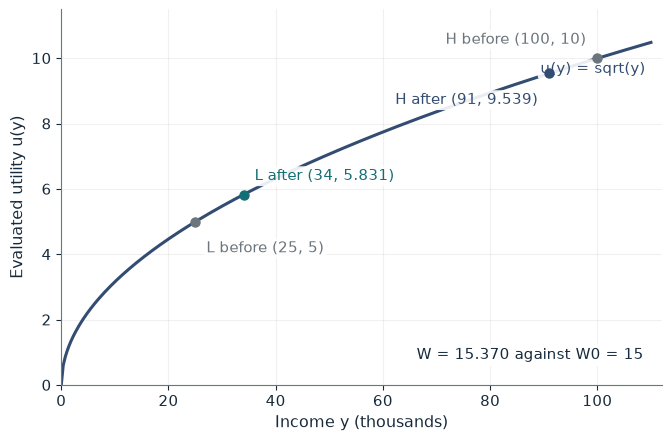

Incomes after (L, H)                  (34, 91)
Welfare W                             15.370
Change from W0 = 15                   +0.370
Total income                          125
Marginal utility at the start (L, H)  0.10, 0.05

Worked steps:
  1. L: 25 + 9 - 0 = 34; H: 100 - 9 = 91
  2. W = 5.831 + 9.539 = 15.370
  3. Change = 15.370 - 15 = +0.370

H gives up 9. Incomes become (34, 91), so W = sqrt(34) + sqrt(91) = 5.831 + 9.539 = 15.370. Evaluated welfare rises by 0.370 from 15. At the start a unit is worth 1 / (2 x 5) = 0.10 to L and 1 / (2 x 10) = 0.05 to H.


In [2]:
show(transfer_picture(t=9, leak=0))

Change one input, `leak`, and hold the others at the book's values:

In [3]:
sweep(transfer_picture, 'leak', [0, 5], {'t': 9}, ['Incomes after (L, H)', 'Welfare W', 'Change from W0 = 15'])

leak | Incomes after (L, H) | Welfare W | Change from W0 = 15
0 | (34, 91) | 15.370 | +0.370
5 | (29, 91) | 14.9246 | -0.0754


A costless transfer of 9 raises welfare by 0.370. If 5 leaks away, welfare is 14.9246, 0.0754 below the start. The book rounds this drop to about 0.076; the exact value rounds to 0.075.

## 2. Atkinson inequality aversion

$$A(\varepsilon)=1-\frac{y_{\mathrm{EDE}}}{\mu}, \qquad y_{\mathrm{EDE},P}=\sqrt{20\cdot80}=\sqrt{1600}=40$$

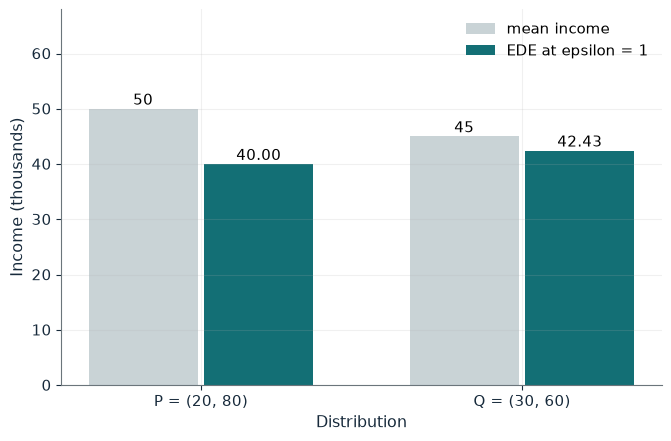

EDE of P             40.00
Atkinson index of P  0.200
EDE of Q             42.43
Atkinson index of Q  0.057
Ranking              Q above P

Worked steps:
  1. EDE(P) = 40.00, EDE(Q) = 42.43
  2. A(P) = 1 - 40.00 / 50 = 0.200
  3. A(Q) = 1 - 42.43 / 45 = 0.057
  4. Ranking: Q higher

With epsilon = 1 the EDE is the geometric mean: sqrt(20 x 80) = 40.00 and sqrt(30 x 60) = 42.43. Q ranks higher. The index is 1 - EDE / mean: 1 - 40.00 / 50 = 0.200 for P and 1 - 42.43 / 45 = 0.057 for Q.


In [4]:
show(atkinson_picture(eps=1))

Change one input, `eps`, and hold the others at the book's values:

In [5]:
sweep(atkinson_picture, 'eps', [0, 0.5, 1, 2], {}, ['EDE of P', 'EDE of Q', 'Ranking'])

eps | EDE of P | EDE of Q | Ranking
0 | 50.00 | 45.00 | P above Q
0.5 | 45.00 | 43.71 | P above Q
1 | 40.00 | 42.43 | Q above P
2 | 32.00 | 40.00 | Q above P


At epsilon 1, Q's EDE of 42.43 beats P's 40 although Q's mean is lower. At 0 and 0.5, P ranks higher. The ranking depends on the stated aversion to inequality.

## 3. Envy-freeness with a side payment

A values the window office at 120 and the quiet one at 80; B values them at 100 and 90. With $t=15$:

$$120-15=105, \quad 80+15=95, \quad 90+15=105, \quad 100-15=85$$

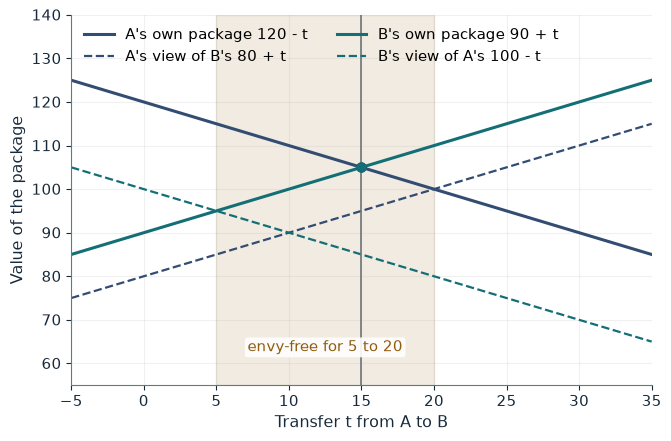

A: own vs other      105 vs 95
B: own vs other      105 vs 85
Envy-free            yes
Envy-free transfers  5 to 20

Worked steps:
  1. A own = 120 - 15 = 105; A's view of B = 80 + 15 = 95
  2. B own = 90 + 15 = 105; B's view of A = 100 - 15 = 85
  3. No envy for A needs t <= (120 - 80) / 2 = 20; for B t >= (100 - 90) / 2 = 5

A: 120 - 15 = 105 against 80 + 15 = 95; A prefers its own (105 > 95). B: 90 + 15 = 105 against 100 - 15 = 85; B prefers its own (105 > 85). The assignment is envy-free.


In [6]:
show(envy_picture(t=15))

Change one input, `t`, and hold the others at the book's values:

In [7]:
sweep(envy_picture, 't', [0, 5, 15, 25], {}, ['A: own vs other', 'B: own vs other', 'Envy-free'])

t | A: own vs other | B: own vs other | Envy-free
0 | 120 vs 80 | 90 vs 100 | no
5 | 115 vs 85 | 95 vs 95 | yes
15 | 105 vs 95 | 105 vs 85 | yes
25 | 95 vs 105 | 115 vs 75 | no


Transfers from 5 to 20 leave no envy; below 5 B envies A and above 20 A envies B.

## 4. Kaldor-Hicks compensation principle

$$S=G-L-R=125-80-30=15, \qquad S'=125-80-50=-5$$

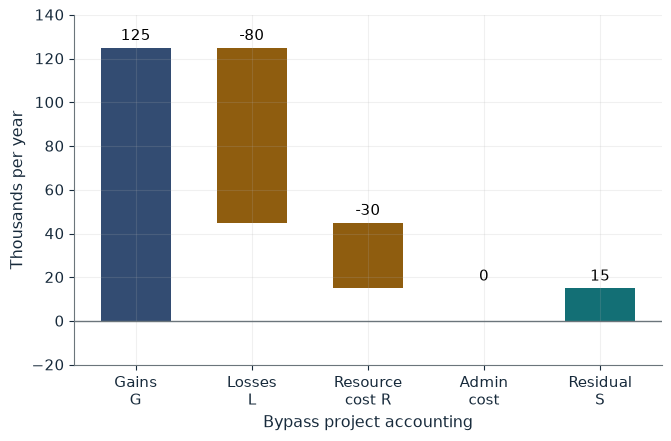

Gains G              125
Losses L             80
Resource cost R      30
Admin cost           0
Residual S           15
Passes Kaldor-Hicks  yes

Worked steps:
  1. G = 80 + 45 = 125
  2. L = 55 + 25 = 80
  3. S = 125 - 80 - 30 - 0 = 15

S = 125 - 80 - 30 - 0 = 15. It passes the potential test, but without payments the losers are worse off, so it is not a Pareto improvement.


In [8]:
show(kaldor_picture(cost=30, admin=0))

Change one input, `cost`, and hold the others at the book's values:

In [9]:
sweep(kaldor_picture, 'cost', [30, 40, 50], {'admin': 4}, ['Residual S', 'Passes Kaldor-Hicks'])

cost | Residual S | Passes Kaldor-Hicks
30 | 11 | yes
40 | 1 | yes
50 | -9 | no


The bypass leaves 15 after covering losses and costs; paying compensation costs 4 and leaves 11. At a resource cost of 50 the residual is -5 and the project fails.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

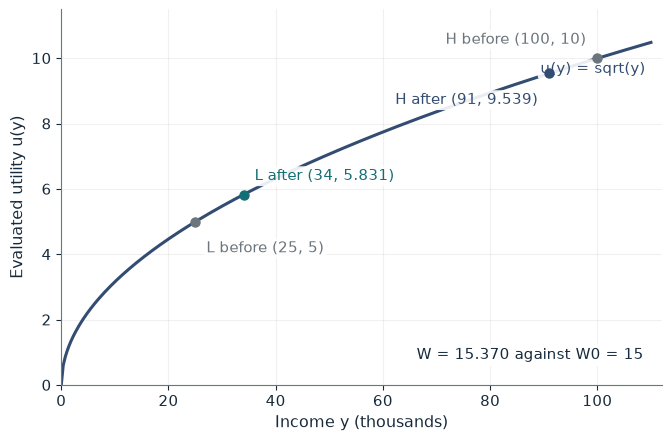

Incomes after (L, H)                  (34, 91)
Welfare W                             15.370
Change from W0 = 15                   +0.370
Total income                          125
Marginal utility at the start (L, H)  0.10, 0.05

Worked steps:
  1. L: 25 + 9 - 0 = 34; H: 100 - 9 = 91
  2. W = 5.831 + 9.539 = 15.370
  3. Change = 15.370 - 15 = +0.370

H gives up 9. Incomes become (34, 91), so W = sqrt(34) + sqrt(91) = 5.831 + 9.539 = 15.370. Evaluated welfare rises by 0.370 from 15. At the start a unit is worth 1 / (2 x 5) = 0.10 to L and 1 / (2 x 10) = 0.05 to H.


In [10]:
show(transfer_picture(t=9, leak=0))

## Practice

**1.** With a transfer of 16 and leakage of 5, what is evaluated welfare?

<details><summary>Answer</summary>

Incomes (36, 84): 6 + 9.165 = 15.165, above 15.

</details>

**2.** What are the two EDEs at epsilon = 0.5?

<details><summary>Answer</summary>

P: 45.00; Q: 43.71. P ranks higher.

</details>

**3.** At t = 25, is the office assignment envy-free?

<details><summary>Answer</summary>

No: A gets 95 but values B's package at 105.

</details>